# **Lab Report: Shooting method to solve Blasius equation**
<h3 align="RIGHT">Submitted by: Kalyana Raama Bheema<h3>

## Problem statement

For steady, incompressible flow of a uniform stream $U_\infty$ over a flat plate, the similarity variable $\eta = y\sqrt{U_\infty/(\nu x)}$ and $u/U_\infty = f'(\eta)$ turn the boundary layer equations into the **Blasius equation**:

$$f''' + \tfrac{1}{2} f f'' = 0, \qquad 0 < \eta < \infty$$

with boundary conditions

$$f(0) = 0, \qquad f'(0) = 0, \qquad f'(\eta) \to 1 \text{ as } \eta \to \infty$$

This is a **boundary value problem (BVP)**: two conditions are at $\eta = 0$ and one is at $\eta = \infty$. Runge–Kutta methods can only solve **initial value problems (IVPs)**, where all conditions are given at the start.

The **shooting method** fixes this: we guess the missing starting value, integrate forward, check how far we miss the condition at infinity, and correct the guess until we hit it.

In [40]:
# do not change line below
from google.colab import files

# import required packages here
import numpy as np
import matplotlib.pyplot as plt

## Step (a): Write the equation as a first-order system

The Blasius equation is third order, but Runge–Kutta works on first-order equations. So we define a vector

$$\mathbf{Y} = \begin{pmatrix} Y_1 \\ Y_2 \\ Y_3 \end{pmatrix} = \begin{pmatrix} f \\ f' \\ f'' \end{pmatrix}$$

and differentiate each component:

- $Y_1' = f' = Y_2$
- $Y_2' = f'' = Y_3$
- $Y_3' = f''' = -\tfrac{1}{2} f f'' = -\tfrac{1}{2} Y_1 Y_3$ (from the Blasius equation)

So the system is

$$\mathbf{Y}' = \mathbf{G}(\mathbf{Y}) = \begin{pmatrix} Y_2 \\ Y_3 \\ -\tfrac{1}{2} Y_1 Y_3 \end{pmatrix}$$


In [41]:
def G(Y):
    f, df, d2f = Y               # f, f', f''
    return np.array([df, d2f, -0.5 * f * d2f])

### Now, The RK3 and RK4 steps

**RK3**, Third order Runge Kutta Method With step size $h = \Delta\eta$:

$$k_1 = G(Y_n), \quad k_2 = G\left(Y_n + \tfrac{h}{2}k_1\right), \quad k_3 = G\left(Y_n - h k_1 + 2h k_2\right)$$
$$Y_{n+1} = Y_n + \tfrac{h}{6}\left(k_1 + 4k_2 + k_3\right)$$

Runge-Kutta's RK3 is third-order accurate: halving $h$ reduces the error by a factor of 8. It requires three evaluations of $f$ per step.

**RK4**, Fourth order Runge-Kutta Method With step size $h = \Delta\eta$:

$$k_1 = G(Y_n), \quad k_2 = G\left(Y_n + \tfrac{h}{2}k_1\right), \quad k_3 = G\left(Y_n + \tfrac{h}{2}k_2\right), \quad k_4 = G(Y_n + h k_3)$$
$$Y_{n+1} = Y_n + \tfrac{h}{6}\left(k_1 + 2k_2 + 2k_3 + k_4\right)$$

Runge-Kutta's RK4 is fourth-order accurate: halving $h$ reduces the error by a factor of 16. It requires four evaluations of $f$ per step.
> [**REF**](https://en.wikipedia.org/wiki/Runge%E2%80%93Kutta_methods)

In [42]:
def rk3_step(Y, h):
    k1 = G(Y)
    k2 = G(Y + h/2 * k1)
    k3 = G(Y - h*k1 + 2*h*k2)
    return Y + h/6 * (k1 + 4*k2 + k3)

def rk4_step(Y, h):
    k1 = G(Y)
    k2 = G(Y + h/2 * k1)
    k3 = G(Y + h/2 * k2)
    k4 = G(Y + h * k3)
    return Y + h/6 * (k1 + 2*k2 + 2*k3 + k4)

## Step (b): The missing initial condition

To start an IVP for a third-order equation we need three values at $\eta = 0$: $f(0)$, $f'(0)$, and $f''(0)$.

We know $f(0) = 0$ and $f'(0) = 0$, but **$f''(0)$ is not given**. Instead we are given $f'(\infty) = 1$.

So the missing initial condition is $f''(0)$, and we call it the **shooting parameter**:

$$s = f''(0)$$

For any guess of $s$, the starting vector is $\mathbf{Y}(0) = (0,\ 0,\ s)$, and we can integrate forward like a normal IVP.
Physically, $f''(0)$ is proportional to the wall shear stress (friction on the plate), so it is the most important number in this problem.

In [43]:
def solve_ivp(s, h, eta_inf, step):
    n = round(eta_inf / h)                  # number of steps
    eta = np.linspace(0, eta_inf, n + 1)
    Y = np.zeros((n + 1, 3))
    Y[0] = [0.0, 0.0, s]                    # f(0)=0, f'(0)=0, f''(0)=s
    for i in range(n):
        Y[i+1] = step(Y[i], h)
    return eta, Y

Let's try trial and error method to see what "shooting" looks like. If 
s is too small, $f'$ ends below 1, if s is too large then $f'$ ends above 1 that implies the correct value of s lies in between

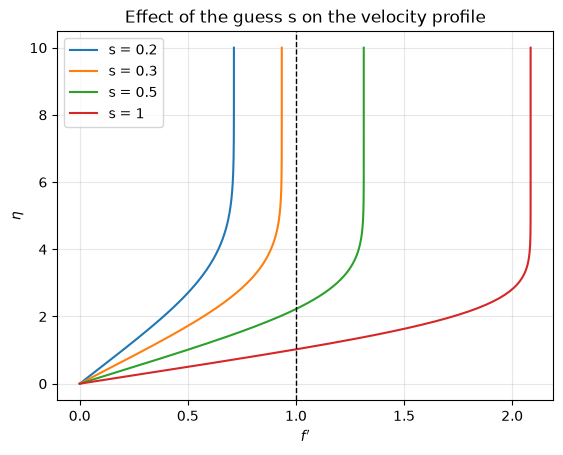

In [44]:
for s_guess in [0.2, 0.3, 0.5, 1]:
    eta, Y = solve_ivp(s_guess, 0.05, 10, rk3_step)
    plt.plot(Y[:, 1], eta, label=f"s = {s_guess}")

plt.axvline(1, color='k', ls='--', lw=1)
plt.ylabel(r'$\eta$'); plt.xlabel(r"$f'$")
plt.title('Effect of the guess s on the velocity profile')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

As we can see from the graph the $s$ or $f''$ value lies between 0.3 and 0.5 from this trial and error method.

## Step (c): Choose $\eta_\infty$, define the residual, and solve for $s$

### Choosing $\eta_\infty$

We need to take a $\eta_\infty$ value where beyond this value flow is basically free stream. we normally choose
$$\eta_\infty = 10$$
### The residual
For a guess $s$, the residual measures how badly we miss the far-field condition:
$$F(s;\eta_\infty) = f'(\eta_\infty; s) - 1$$
The correct $s$ is the **root** of $F(s) = 0$.

In [45]:
eta_inf = 10
def F(s, h, eta_inf, step):
    eta, Y = solve_ivp(s, h, eta_inf, step)
    return Y[-1, 1] - 1.0          # f'(eta_inf) - 1

### Root finding with the bisection method

The **bisection method** is the simplest and safest root finder. The idea:

1. Find two values $a$ and $b$ where $F(a)$ and $F(b)$ have **opposite signs**. Then the root must lie between them (this is called a *bracket*).
2. Take the midpoint $c = (a+b)/2$ and compute $F(c)$.
3. Keep the half that still has a sign change:
   - if $F(a)$ and $F(c)$ have opposite signs, the root is in $[a, c]$, so set $b = c$;
   - otherwise the root is in $[c, b]$, so set $a = c$.
4. Repeat until the interval is small enough.

**Tolerance:** We stop when the half-width of the interval is below $10^{-12}$. Because the root is always inside the interval.\
**Iterations:** After $k$ iterations the half-width is $(b-a)/2^{k+1}$. Setting $0.9/2^{k+1} < 10^{-12}$ gives $k \approx 39$ iterations.


In [ ]:
def bisection(h, eta_inf, step, a=0.2, b=1.0, tol=1e-12):
    Fa = F(a, h, eta_inf, step)
    Fb = F(b, h, eta_inf, step)
    if Fa * Fb > 0:
        raise ValueError("F(a) and F(b) have the same sign")
    while (b - a) / 2 > tol:
        c = (a + b) / 2
        Fc = F(c, h, eta_inf, step)
        if Fa * Fc < 0:      # root is in [a, c]
            b = c
        else:                # root is in [c, b]
            a, Fa = c, Fc
    return (a + b) / 2

## Step (d): RK3 for different step sizes and the order of accuracy

### How we measure the error

The exact $f''(0)$ has no closed-form formula. So we compute a **reference value** with RK3 and a very small step, $\Delta\eta = 0.001$. This is far more accurate than any of our test runs, so we treat it as "exact".

The error for each step size is $E(\Delta\eta) = |s(\Delta\eta) - s_{\text{ref}}|$.

In [58]:
sref= bisection(0.001, eta_inf, rk3_step)
print(f"reference value for s = {sref}")

reference value for s = 0.33205733720315045


### How does a log-log plot shows the order
If a method has order $p$, then $E \approx C\,(\Delta\eta)^p$. Taking logs of both sides:

$$\log E = \log C + p \,\log(\Delta\eta)$$

This is a straight line, and its **slope is $p$**. So on a log–log plot, RK3 should give slope 3.
We can also compute the order between two consecutive step sizes :

$$p_{\text{obs}} = \frac{\log\left(E(2\Delta\eta)/E(\Delta\eta)\right)}{\log 2}$$

 d_eta              s       error  order
 0.400   0.3319771448   8.019e-05   --
 0.200   0.3320495982   7.739e-06   3.37
 0.100   0.3320565334   8.038e-07   3.27
 0.050   0.3320572476   8.961e-08   3.17
 0.025   0.3320573267   1.050e-08   3.09


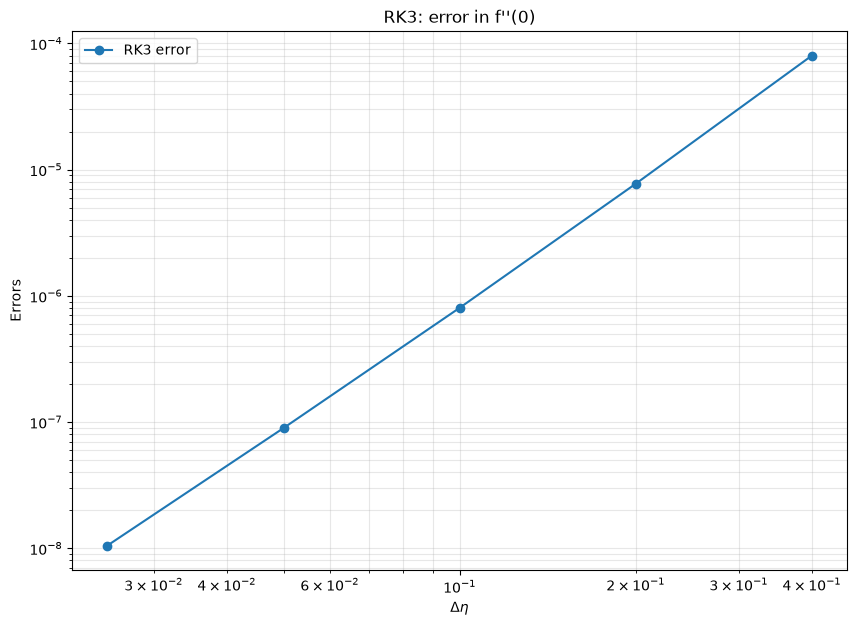

In [53]:
hs = [0.4, 0.2, 0.1, 0.05, 0.025]

def order(step, name, p):
    errs = []
    print(f"{'d_eta':>6} {'s':>14} {'error':>11} {'order':>6}")
    for i, h in enumerate(hs):
        s = bisection(h, eta_inf, step)
        errs.append(abs(s - sref))
        if i == 0:
            order = "  --"
        else:
            order = f"{np.log(errs[i-1] / errs[i]) / np.log(2):6.2f}"
        print(f"{h:6.3f} {s:14.10f} {errs[i]:11.3e} {order}")

    plt.figure(figsize=(10, 7)) 
    plt.loglog(hs, errs, 'o-', label=f'{name} error')
    plt.xlabel(r'$\Delta\eta$'); plt.ylabel(r'Errors')
    plt.title(f'{name}: error in f\'\'(0)')
    plt.legend()
    plt.grid(True, which='both', alpha=0.3)
    plt.show()
    
order(rk3_step, 'RK3', 3)

The order starts from 3.37 as the step size goes smaller that order gradually decreases and goes to 3.09 at 0.025. So, we can infer that as the step size decreases the order tends to 3. So, Runge Kutta 3 method is 3rd order accurate.

## Step (e): Plot $f$, $f'$, $f''$ (RK3)

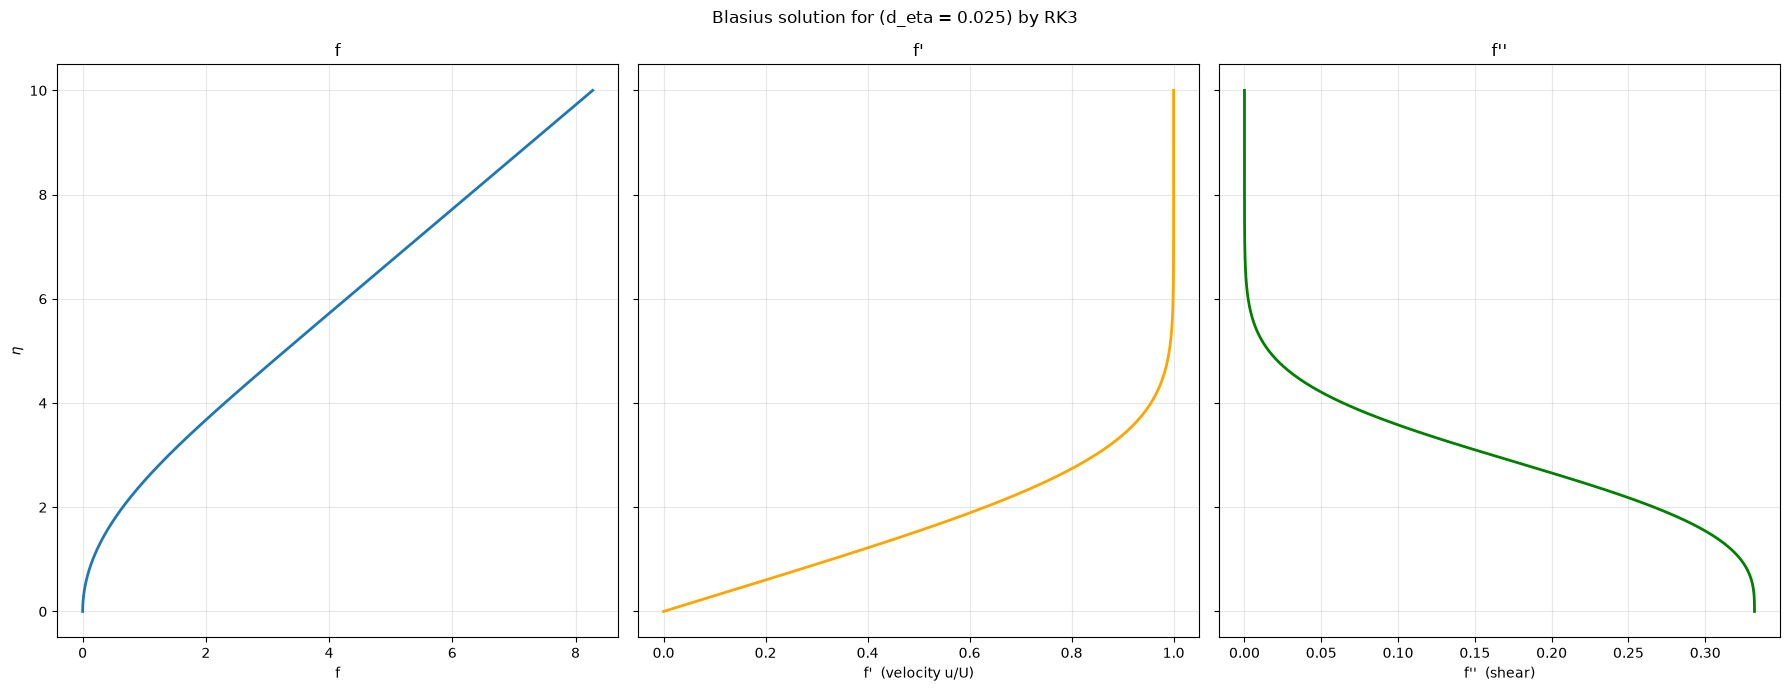

In [59]:
h = 0.025
s = bisection(h, eta_inf, rk3_step)
eta, Y = solve_ivp(s, h, eta_inf, rk3_step)

fig, ax = plt.subplots(1, 3, figsize=(18, 7), sharey=True)

# f
ax[0].plot(f, eta, lw=2)
ax[0].set_xlabel("f")
ax[0].set_title("f")

# f'
ax[1].plot(df, eta, lw=2, color='orange')
ax[1].set_xlabel("f'  (velocity u/U)")
ax[1].set_title("f'")

# f''
ax[2].plot(d2f, eta, lw=2, color='green')
ax[2].set_xlabel("f''  (shear)")
ax[2].set_title("f''")

ax[0].set_ylabel(r"$\eta$")       # only the first panel needs the y-label
for a in ax:
    a.grid(alpha=0.3)

fig.suptitle("Blasius solution for (d_eta = 0.025) by RK3")
plt.tight_layout()
plt.show()

## Step (d) and (e): RK4 for different step sizes and the order of accuracy and plotting $f$, $f'$, $f''$

Same was as we did for RK3 we will do for RK4 and have some words about order of RK4

 d_eta              s       error  order
 0.400   0.3320588158   1.479e-06   --
 0.200   0.3320574574   1.202e-07   3.62
 0.100   0.3320573456   8.408e-09   3.84
 0.050   0.3320573378   5.544e-10   3.92
 0.025   0.3320573372   3.638e-11   3.93


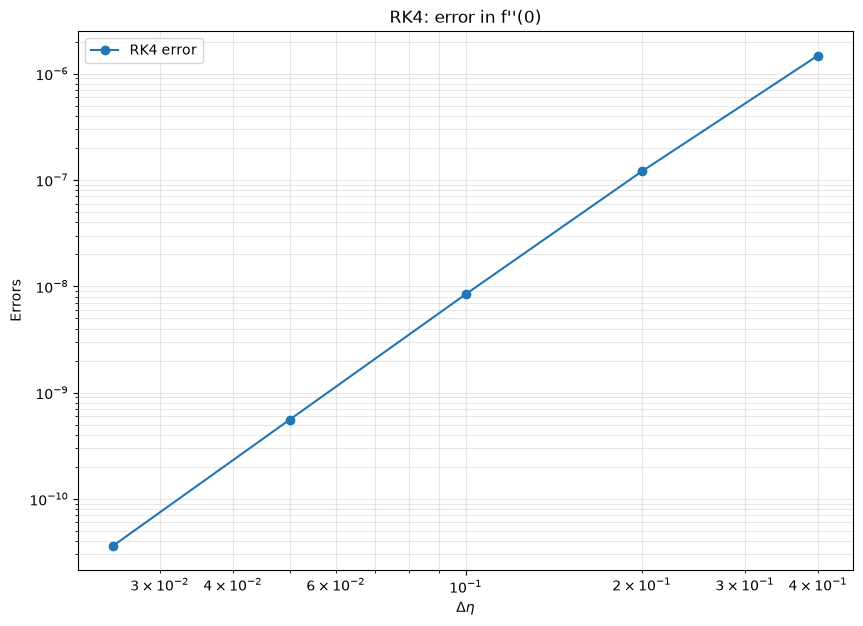

In [54]:
sref = bisection(0.001, eta_inf, rk4_step)
hs = [0.4, 0.2, 0.1, 0.05, 0.025]

def order(step, name, p):
    errs = []
    print(f"{'d_eta':>6} {'s':>14} {'error':>11} {'order':>6}")
    for i, h in enumerate(hs):
        s = bisection(h, eta_inf, step)
        errs.append(abs(s - sref))
        if i == 0:
            order = "  --"
        else:
            order = f"{np.log(errs[i-1] / errs[i]) / np.log(2):6.2f}"
        print(f"{h:6.3f} {s:14.10f} {errs[i]:11.3e} {order}")

    plt.figure(figsize=(10, 7)) 
    plt.loglog(hs, errs, 'o-', label=f'{name} error')
    plt.xlabel(r'$\Delta\eta$'); plt.ylabel(r'Errors')
    plt.title(f'{name}: error in f\'\'(0)')
    plt.legend()
    plt.grid(True, which='both', alpha=0.3)
    plt.show()
    
order(rk4_step, 'RK4', 4)

As we can infer from ther table above the order value is 3.62 for step size 0.2 and as Step size reduces the order also slowly increasea and reaches 3.93 for step size 0.025, and slowly the value is tending to 4. So, we can infer that Runge Kutta 4 method is Fourth-order accurate.

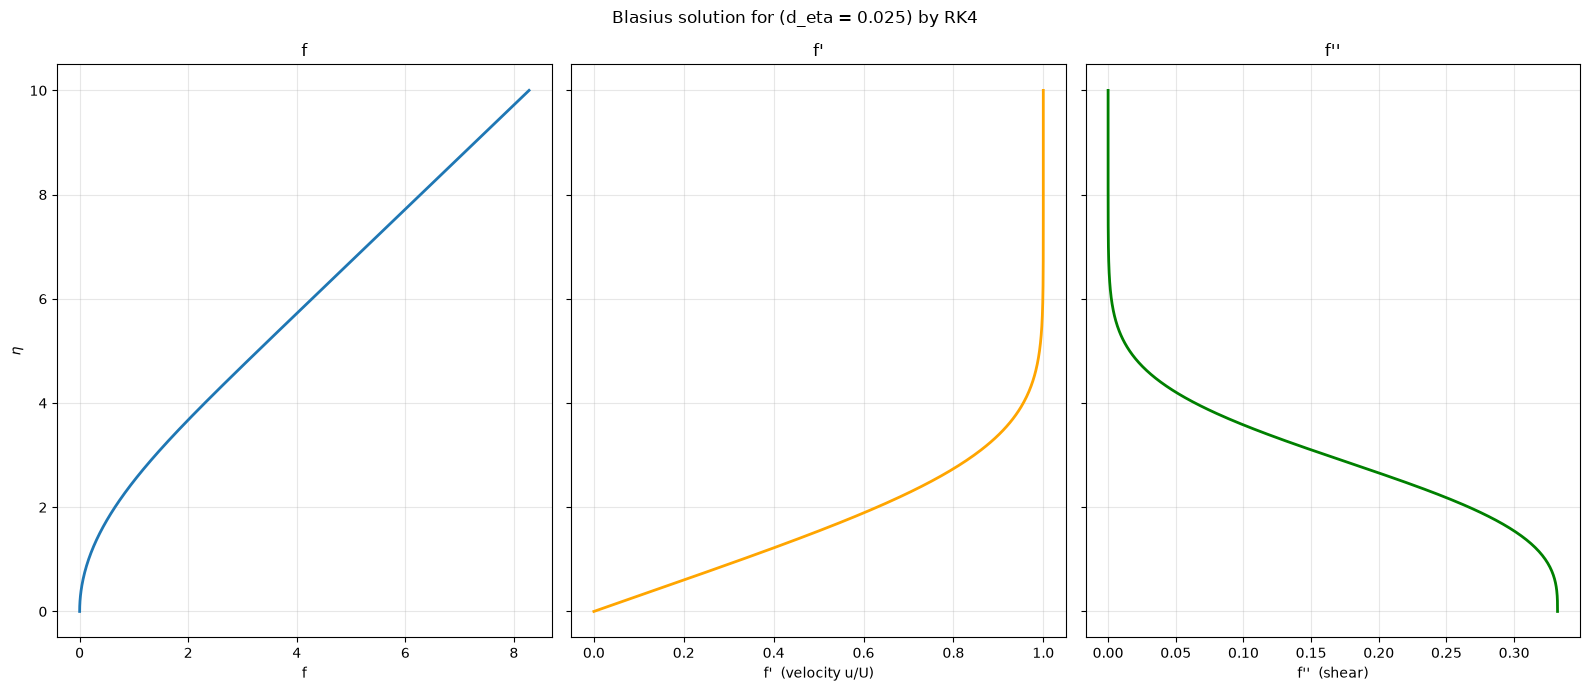

In [61]:
h = 0.025
s = bisection(h, eta_inf, rk4_step)
eta, Y = solve_ivp(s, h, eta_inf, rk4_step)

fig, ax = plt.subplots(1, 3, figsize=(16, 7), sharey=True)

# f
ax[0].plot(f, eta, lw=2)
ax[0].set_xlabel("f")
ax[0].set_title("f")

# f'
ax[1].plot(df, eta, lw=2, color='orange')
ax[1].set_xlabel("f'  (velocity u/U)")
ax[1].set_title("f'")

# f''
ax[2].plot(d2f, eta, lw=2, color='green')
ax[2].set_xlabel("f''  (shear)")
ax[2].set_title("f''")

ax[0].set_ylabel(r"$\eta$")       # only the first panel needs the y-label
for a in ax:
    a.grid(alpha=0.3)

fig.suptitle("Blasius solution for (d_eta = 0.025) by RK4")
plt.tight_layout()
plt.show()

As we can infer from all graphs above the RK3 and RK4 methods gave us similar results when step size is small.

## Step (g): Check against the known value

In [62]:
s3= bisection(0.025, eta_inf, rk3_step)
s4= bisection(0.025, eta_inf, rk4_step)
print(f"RK3:  f''(0) = {s3:}")
print(f"RK4:  f''(0) = {s4}")
print(f"Known value  ~ 0.332")
print("Agrees to three digits:", round(s3, 3) == 0.332 and round(s4, 3) == 0.332)

RK3:  f''(0) = 0.33205732670103333
RK4:  f''(0) = 0.3320573372395302
Known value  ~ 0.332
Agrees to three digits: True


Both methods give $f''(0) = 0.33205$, which agrees with the known Blasius value $0.332$ to three digits (actually to five). **The check was success.**

## Conclusions

1. The third-order Blasius BVP was rewritten as a first-order system $\mathbf{Y}' = \mathbf{G}(\mathbf{Y})$ and solved by shooting on the unknown wall value $s = f''(0)$.
2. With $\eta_\infty = 10$ and the bisection method (bracket $[0.1, 1.0]$, tolerance $10^{-12}$), the shooting converged in about 39 iterations every time. Bisection is slower than secant, but it is guaranteed to converge once the root is inside the values mentioned.
3. The log–log plots confirm the expected orders of accuracy: about **3 for RK3** and about **4 for RK4**.
4. Both methods give **$f''(0) = 0.33205$**, matching the known value $0.332$.